In [97]:
!pip install -q pymupdf

,ID,Resume_str,Resume_html,Category
0,16852973,HR ADMINISTRATOR/MARKETING ASSOCIATE\...,"<div class=""fontsize fontface vmargins hmargin...",HR
1,22323967,"HR SPECIALIST, US HR OPERATIONS ...","<div class=""fontsize fontface vmargins hmargin...",HR
2,33176873,HR DIRECTOR Summary Over 2...,"<div class=""fontsize fontface vmargins hmargin...",HR
3,27018550,HR SPECIALIST Summary Dedica...,"<div class=""fontsize fontface vmargins hmargin...",HR
4,17812897,HR MANAGER Skill Highlights ...,"<div class=""fontsize fontface vmargins hmargin...",HR


Dataset Shape: (2484, 4)
Columns: ['ID', 'Resume_str', 'Resume_html', 'Category']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2484 entries, 0 to 2483
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   ID           2484 non-null   int64 
 1   Resume_str   2484 non-null   object
 2   Resume_html  2484 non-null   object
 3   Category     2484 non-null   object
dtypes: int64(1), object(3)
memory usage: 77.8+ KB
Missing Values:
ID             0
Resume_str     0
Resume_html    0
Category       0
dtype: int64
Duplicate Records: 0
Cleaned Dataset Shape: (2481, 2)


,resume,category
0,HR ADMINISTRATOR/MARKETING ASSOCIATE\n\nHR ADM...,HR
1,"HR SPECIALIST, US HR OPERATIONS Summary ...",HR
2,HR DIRECTOR Summary Over 20 years e...,HR
3,"HR SPECIALIST Summary Dedicated, Driv...",HR
4,HR MANAGER Skill Highlights ...,HR


Unique Categories: ['HR' 'DESIGNER' 'INFORMATION-TECHNOLOGY' 'TEACHER' 'ADVOCATE'
 'BUSINESS-DEVELOPMENT' 'HEALTHCARE' 'FITNESS' 'AGRICULTURE' 'BPO' 'SALES'
 'CONSULTANT' 'DIGITAL-MEDIA' 'AUTOMOBILE' 'CHEF' 'FINANCE' 'APPAREL'
 'ENGINEERING' 'ACCOUNTANT' 'CONSTRUCTION' 'PUBLIC-RELATIONS' 'BANKING'
 'ARTS' 'AVIATION']
Total Categories: 24
category
INFORMATION-TECHNOLOGY    120
BUSINESS-DEVELOPMENT      119
ADVOCATE                  118
CHEF                      118
ENGINEERING               118
ACCOUNTANT                118
FINANCE                   117
FITNESS                   117
SALES                     116
AVIATION                  116
BANKING                   115
HEALTHCARE                115
CONSULTANT                115
CONSTRUCTION              112
PUBLIC-RELATIONS          111
HR                        110
DESIGNER                  107
ARTS                      103
TEACHER                   102
APPAREL                    97
DIGITAL-MEDIA              96
AGRICULTURE          

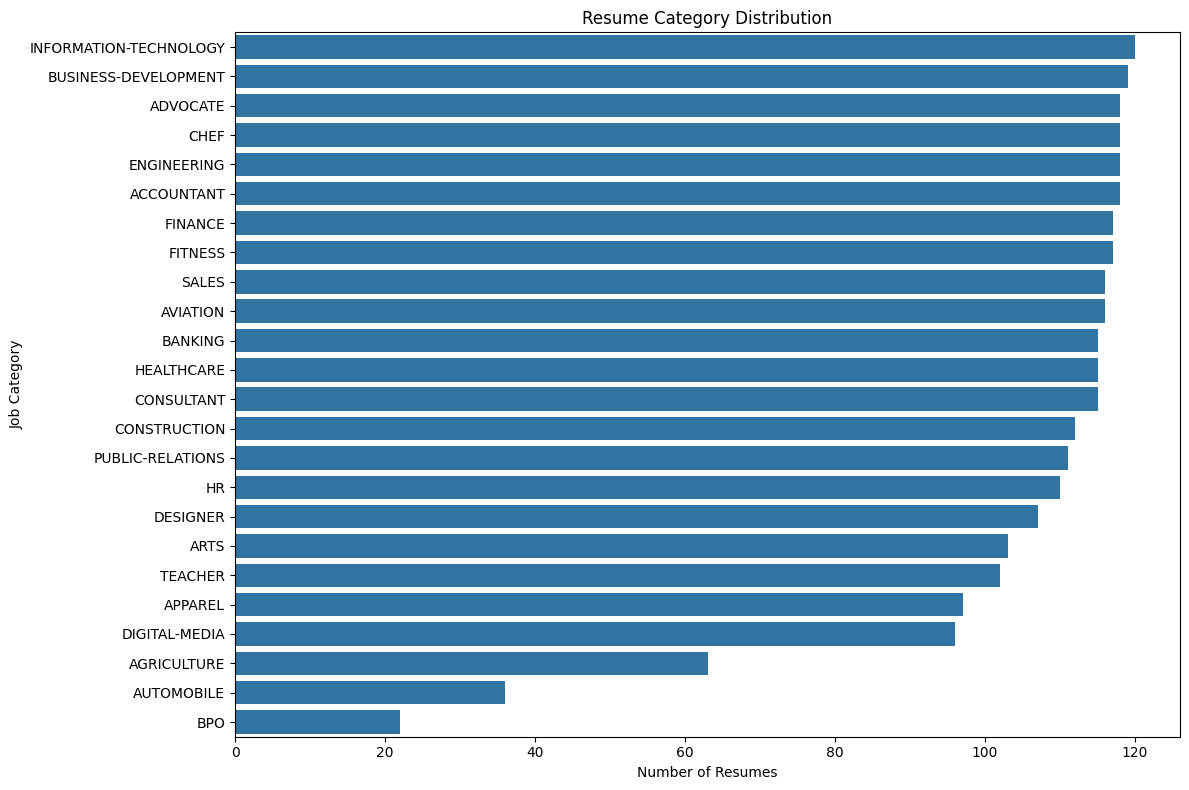

,resume_length,word_count
count,2481.000000,2481.000000
mean,6284.997582,811.770254
std,2767.884259,370.849927
min,869.000000,113.000000
25%,5147.000000,651.000000
50%,5875.000000,757.000000
75%,7215.000000,933.000000
max,38813.000000,5190.000000


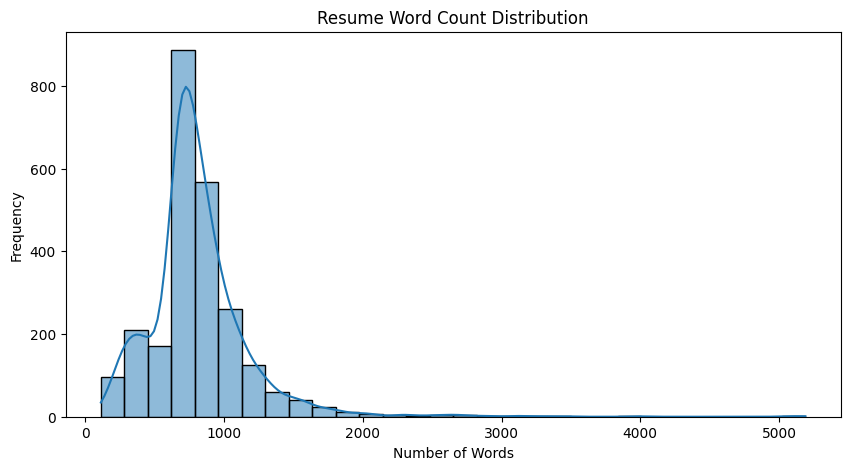

,word_count
category,
BPO,974.227273
INFORMATION-TECHNOLOGY,926.583333
PUBLIC-RELATIONS,889.315315
HEALTHCARE,881.773913
CONSULTANT,879.704348
AGRICULTURE,856.285714
HR,853.727273
CONSTRUCTION,852.714286
ADVOCATE,848.500000


Conflicting Resumes: 0
Final Dataset Shape: (2481, 5)


,resume,category,resume_length,word_count,cleaned_resume
0,HR ADMINISTRATOR/MARKETING ASSOCIATE\n\nHR ADM...,HR,5429,674,hr administrator marketing associate hr admini...
1,"HR SPECIALIST, US HR OPERATIONS Summary ...",HR,5560,708,hr specialist us hr operations summary versati...
2,HR DIRECTOR Summary Over 20 years e...,HR,7706,1017,hr director summary 20 years experience recrui...
3,"HR SPECIALIST Summary Dedicated, Driv...",HR,2839,379,hr specialist summary dedicated driven dynamic...
4,HR MANAGER Skill Highlights ...,HR,9160,1206,hr manager skill highlights hr skills hr depar...


Training Samples: 1984
Testing Samples: 497
category
INFORMATION-TECHNOLOGY    96
BUSINESS-DEVELOPMENT      95
ACCOUNTANT                94
ENGINEERING               94
ADVOCATE                  94
CHEF                      94
FITNESS                   93
FINANCE                   93
SALES                     93
AVIATION                  93
HEALTHCARE                92
BANKING                   92
CONSULTANT                92
CONSTRUCTION              90
PUBLIC-RELATIONS          89
HR                        88
DESIGNER                  86
ARTS                      82
TEACHER                   82
APPAREL                   78
DIGITAL-MEDIA             77
AGRICULTURE               50
AUTOMOBILE                29
BPO                       18
Name: count, dtype: int64
category
FINANCE                   24
BUSINESS-DEVELOPMENT      24
ACCOUNTANT                24
CHEF                      24
ENGINEERING               24
FITNESS                   24
INFORMATION-TECHNOLOGY    24
ADVOCATE     

,Model,CV_F1_Score,Standard_Deviation
0,SVM,0.658022,0.020717
1,Random Forest,0.640865,0.018988
2,Logistic Regression,0.585732,0.010809
3,Naive Bayes,0.473539,0.014824


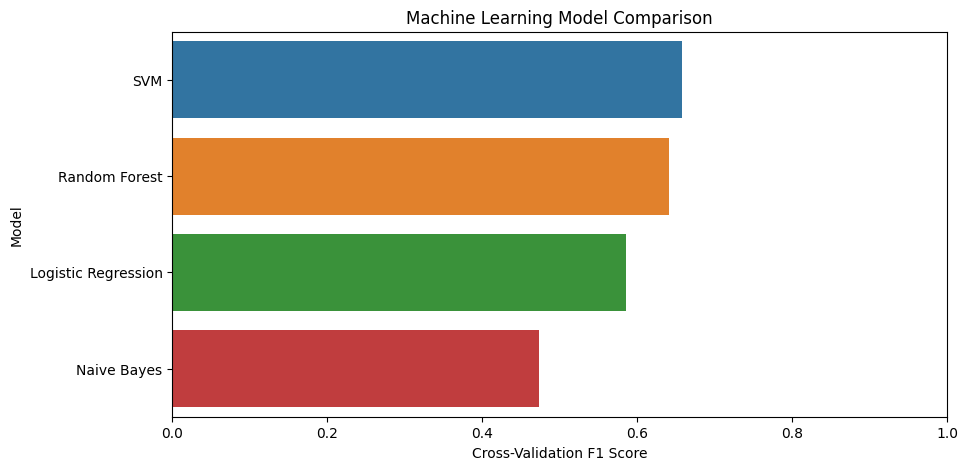

Best Model: SVM
Best Model: SVM
Training Accuracy: 0.9985
Testing Accuracy: 0.7183
Precision: 0.7065
Recall: 0.6799
F1 Score: 0.6797
Accuracy Gap: 0.2802
                        precision    recall  f1-score   support

            ACCOUNTANT       0.62      0.88      0.72        24
              ADVOCATE       0.61      0.71      0.65        24
           AGRICULTURE       0.80      0.62      0.70        13
               APPAREL       0.58      0.37      0.45        19
                  ARTS       0.58      0.33      0.42        21
            AUTOMOBILE       1.00      0.43      0.60         7
              AVIATION       0.94      0.74      0.83        23
               BANKING       0.85      0.74      0.79        23
                   BPO       0.00      0.00      0.00         4
  BUSINESS-DEVELOPMENT       0.69      0.83      0.75        24
                  CHEF       0.81      0.71      0.76        24
          CONSTRUCTION       0.79      0.86      0.83        22
            C

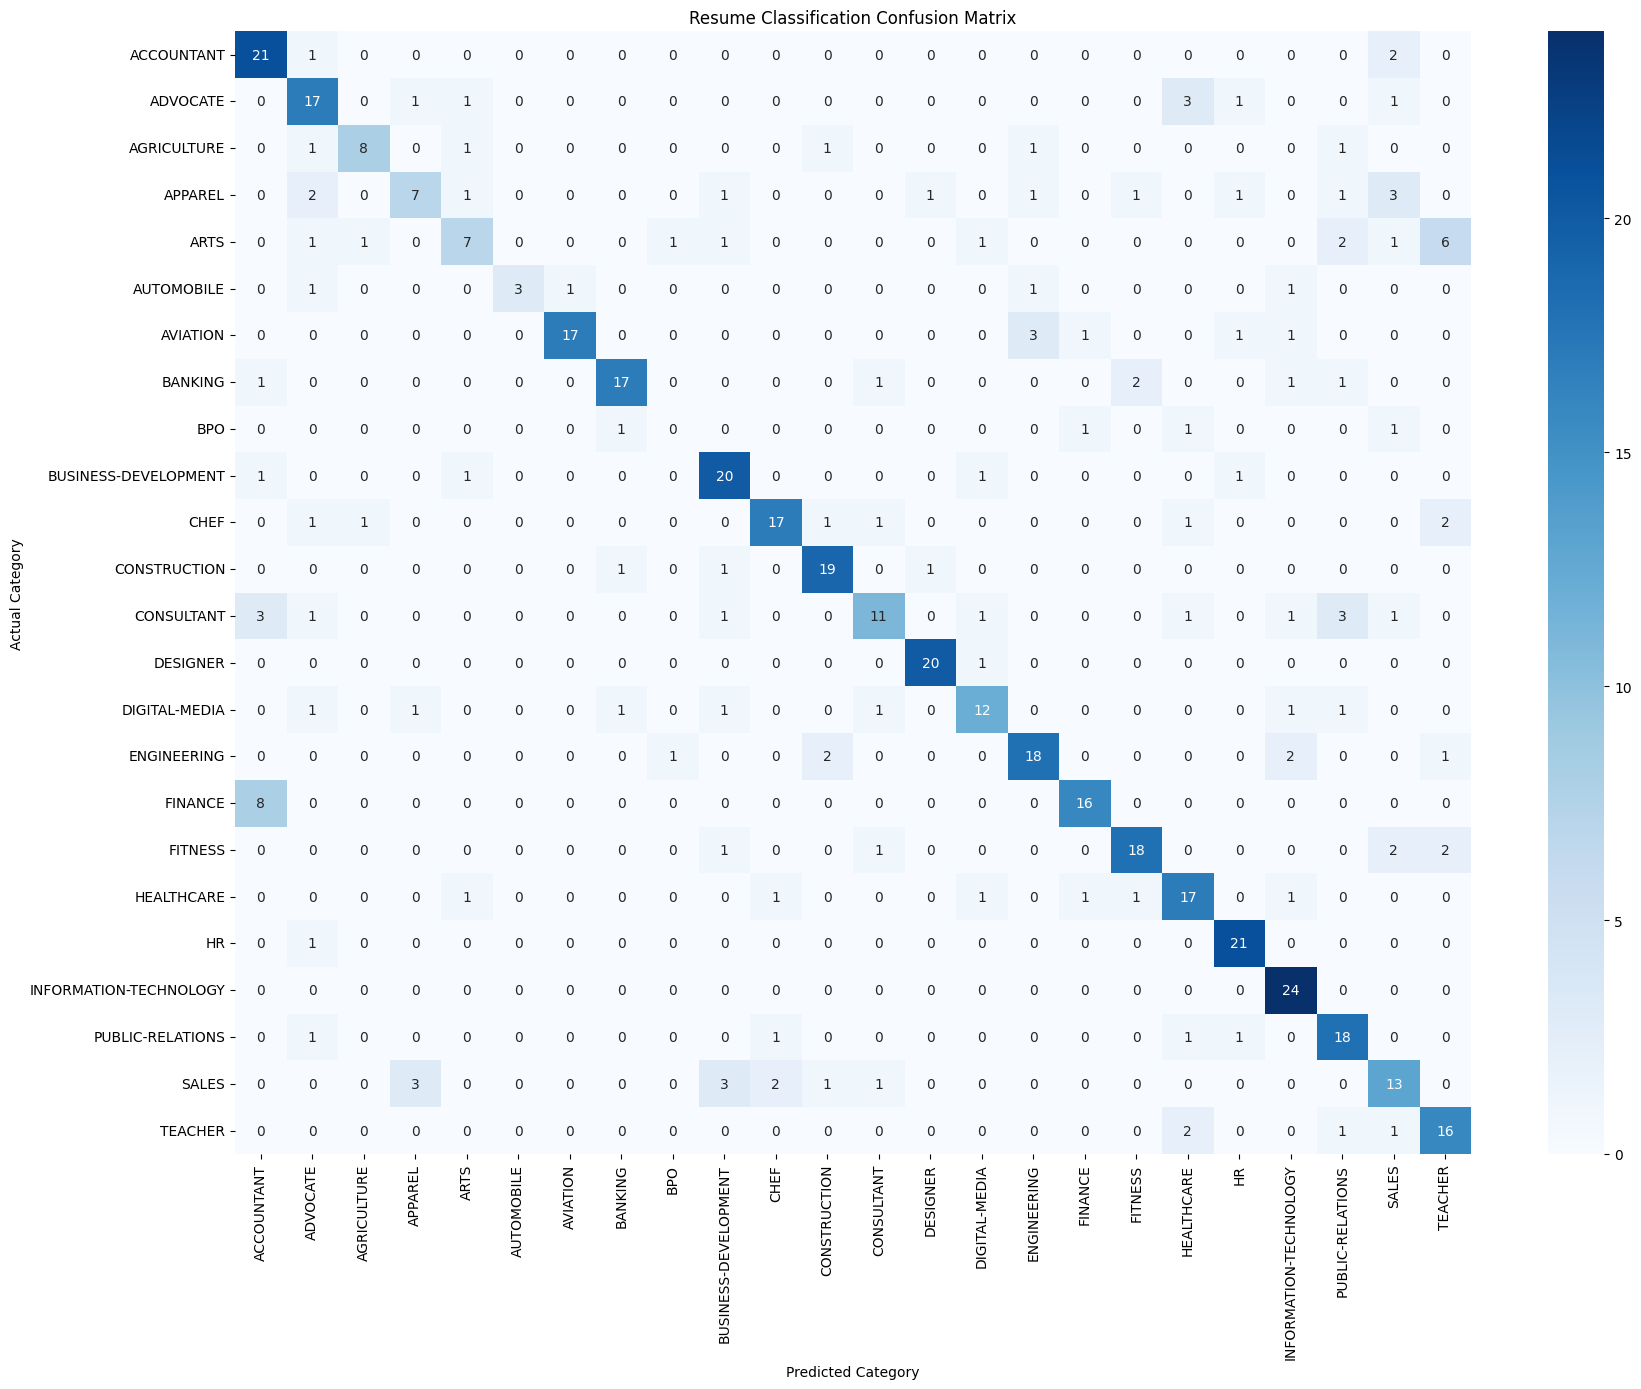

,Metric,Score,Percentage
0,Accuracy,0.718310,71.83
1,Precision,0.706521,70.65
2,Recall,0.679940,67.99
3,F1 Score,0.679673,67.97


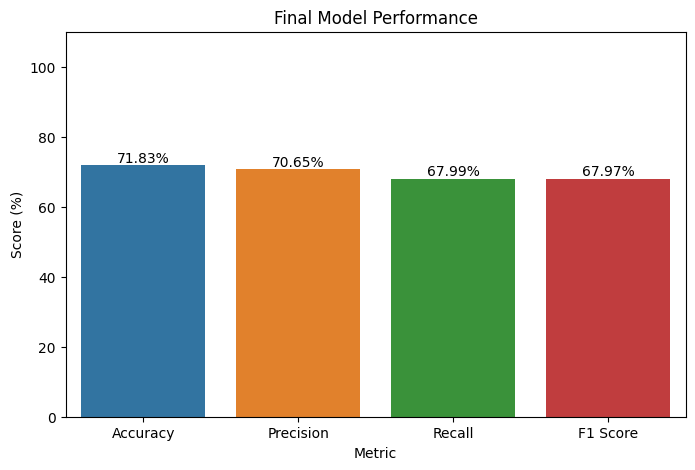

Predicted Category: BANKING
Model and Vectorizer Saved Successfully


In [98]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import re
import nltk
import fitz
import joblib
from nltk.corpus import stopwords
from google.colab import files
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import (train_test_split,cross_val_score,StratifiedKFold)
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import LinearSVC
from sklearn.metrics import (accuracy_score,precision_score,recall_score,f1_score,classification_report,confusion_matrix)
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.pipeline import Pipeline
from sklearn.base import clone

df = pd.read_csv(
    "/content/Resume.csv",
    engine="python",
    on_bad_lines="warn"
)

display(df.head())

print("Dataset Shape:", df.shape)
print("Columns:", df.columns.tolist())

df.info()

print("Missing Values:")
print(df.isnull().sum())

print("Duplicate Records:", df.duplicated().sum())

df = df[["Resume_str", "Category"]].copy()

df = df.dropna()

df = df.drop_duplicates()

df = df.rename(columns={
    "Resume_str": "resume",
    "Category": "category"
})

df["resume"] = df["resume"].astype(str).str.strip()
df["category"] = df["category"].astype(str).str.strip()

df = df[
    (df["resume"] != "") &
    (df["category"] != "")
]

df = df.reset_index(drop=True)

print("Cleaned Dataset Shape:", df.shape)

display(df.head())

print("Unique Categories:", df["category"].unique())

print("Total Categories:", df["category"].nunique())

print(df["category"].value_counts())

plt.figure(figsize=(12, 8))

sns.countplot(
    data=df,
    y="category",
    order=df["category"].value_counts().index
)

plt.title("Resume Category Distribution")

plt.xlabel("Number of Resumes")
plt.ylabel("Job Category")
plt.tight_layout()
plt.savefig("Resume Category Distribution.png")
plt.show()

df["resume_length"] = df["resume"].apply(len)

df["word_count"] = df["resume"].apply(
    lambda x: len(x.split())
)

display(df[["resume_length", "word_count"]].describe())

plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="word_count",
    kde=True,
    bins=30
)

plt.title("Resume Word Count Distribution")
plt.xlabel("Number of Words")
plt.ylabel("Frequency")
plt.savefig("Resume Word Count Distribution.png")
plt.show()

display(
    df.groupby("category")["word_count"]
    .mean()
    .sort_values(ascending=False)
)

nltk.download("stopwords", quiet=True)

stop_words = set(stopwords.words("english"))

def clean_resume(text):
    text = text.lower()
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"\S+@\S+", " ", text)
    text = re.sub(r"<.*?>", " ", text)
    text = re.sub(r"[^a-z0-9+#.\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    text = " ".join(
        word for word in text.split()
        if word not in stop_words
    )
    return text

df["cleaned_resume"] = df["resume"].apply(clean_resume)

df = df[df["cleaned_resume"].str.strip() != ""]

conflicts = df.groupby("cleaned_resume")["category"].nunique()
conflicting_resumes = conflicts[conflicts > 1].index
print("Conflicting Resumes:", len(conflicting_resumes))

df = df[~df["cleaned_resume"].isin(conflicting_resumes)]

df = df.drop_duplicates(subset=["cleaned_resume"])
df = df.reset_index(drop=True)

print("Final Dataset Shape:", df.shape)
display(df.head())

X = df["cleaned_resume"]
y = df["category"]

if y.value_counts().min() < 2:
    raise ValueError("Some categories have insufficient samples.")

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Samples:", len(X_train))
print("Testing Samples:", len(X_test))

print(y_train.value_counts())
print(y_test.value_counts())

tfidf = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2),
    min_df=2
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Training Shape:", X_train_tfidf.shape)
print("Testing Shape:", X_test_tfidf.shape)
print(tfidf.get_feature_names_out()[:30])

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),
    "Naive Bayes": MultinomialNB(),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ),
    "SVM": LinearSVC(
        random_state=42
    )
}

n_splits = min(5, int(y_train.value_counts().min()))
if n_splits < 2:
    raise ValueError("Insufficient samples for cross-validation.")

cv = StratifiedKFold(
    n_splits=n_splits,
    shuffle=True,
    random_state=42
)

cv_results = []
for name, model in models.items():
    pipeline = Pipeline([
        ("tfidf", clone(tfidf)),
        ("model", clone(model))
    ])
    scores = cross_val_score(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring="f1_macro",
        error_score="raise"
    )
    cv_results.append({
        "Model": name,
        "CV_F1_Score": scores.mean(),
        "Standard_Deviation": scores.std()
    })

cv_results_df = pd.DataFrame(cv_results)
cv_results_df = cv_results_df.sort_values(
    by="CV_F1_Score",
    ascending=False
).reset_index(drop=True)

display(cv_results_df)

plt.figure(figsize=(10, 5))
sns.barplot(
    data=cv_results_df,
    x="CV_F1_Score",
    y="Model",
    hue="Model",
    legend=False
)
plt.title("Machine Learning Model Comparison")
plt.xlabel("Cross-Validation F1 Score")
plt.xlim(0, 1)
plt.savefig("Resume Word Count Distribution.png")
plt.show()

best_model_name = cv_results_df.iloc[0]["Model"]
best_model = clone(models[best_model_name])
best_model.fit(X_train_tfidf, y_train)
print("Best Model:", best_model_name)

y_train_pred = best_model.predict(X_train_tfidf)
y_pred = best_model.predict(X_test_tfidf)

train_accuracy = accuracy_score(y_train, y_train_pred)
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, average="macro", zero_division=0)
recall = recall_score(y_test, y_pred, average="macro", zero_division=0)
f1 = f1_score(y_test, y_pred, average="macro", zero_division=0)

print("Best Model:", best_model_name)
print(f"Training Accuracy: {train_accuracy:.4f}")
print(f"Testing Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1 Score: {f1:.4f}")
print(f"Accuracy Gap: {train_accuracy - accuracy:.4f}")

print(classification_report(
    y_test,
    y_pred,
    zero_division=0
))

labels = best_model.classes_
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=labels
)

plt.figure(figsize=(18, 14))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels
)
plt.title("Resume Classification Confusion Matrix")
plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")
plt.savefig("Resume Classification Confusion Matrix.png")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

performance = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score"
    ],
    "Score": [
        accuracy,
        precision,
        recall,
        f1
    ]
})

performance["Percentage"] = (
    performance["Score"] * 100
).round(2)

display(performance)

plt.figure(figsize=(8, 5))
ax = sns.barplot(
    data=performance,
    x="Metric",
    y="Percentage",
    hue="Metric",
    legend=False
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%")

plt.title("Final Model Performance")
plt.savefig("Final Model Performance")
plt.ylabel("Score (%)")
plt.ylim(0, 110)
plt.show()

sample_resume = """
Python, SQL, Pandas, NumPy, Machine Learning,
Data Visualization, Power BI, Statistical Analysis,
Exploratory Data Analysis and Scikit-learn.
"""

cleaned_text = clean_resume(sample_resume)
vectorized_text = tfidf.transform([cleaned_text])

if vectorized_text.nnz == 0:
    print("Insufficient recognized text.")
else:
    prediction = best_model.predict(vectorized_text)
    print("Predicted Category:", prediction[0])

skills = [
    "python", "sql", "pandas", "numpy",
    "machine learning", "deep learning",
    "power bi", "excel", "statistics",
    "matplotlib", "seaborn", "scikit-learn",
    "tensorflow", "pytorch", "tableau",
    "data analysis", "nlp", "git",
    "github", "streamlit", "aws",
    "spark", "pyspark", "langchain",
    "rag", "llm", "docker", "fastapi",
    "flask", "mongodb", "mysql",
    "postgresql", "computer vision",
    "opencv", "keras", "rest api",
    "artificial intelligence", "generative ai",
    "data visualization", "feature engineering",
    "java", "javascript", "c++", "c#",
    "html", "css", "linux", "azure",
    "kubernetes"
]

def extract_skills(text):
    text = text.lower()
    text = re.sub(r"\s+", " ", text)
    extracted_skills = set()
    for skill in skills:
        pattern = r"(?<!\w)" + re.escape(skill) + r"(?!\w)"
        if re.search(pattern, text):
            extracted_skills.add(skill)
    return extracted_skills

def extract_pdf_text(filepath):
    text = ""
    with fitz.open(filepath) as document:
        for page in document:
            text += page.get_text() + "\n"
    return text.strip()

def analyze_resume(resume_text, job_description):
    if not resume_text.strip():
        return {"Error": "Resume text is empty"}
    if not job_description.strip():
        return {"Error": "Job description is empty"}

    cleaned_resume = clean_resume(resume_text)
    cleaned_jd = clean_resume(job_description)

    resume_vector = tfidf.transform([cleaned_resume])
    jd_vector = tfidf.transform([cleaned_jd])

    if resume_vector.nnz == 0 or jd_vector.nnz == 0:
        return {"Error": "Insufficient recognized text"}

    category = best_model.predict(resume_vector)[0]
    similarity = cosine_similarity(resume_vector, jd_vector)[0][0] * 100

    resume_skills = extract_skills(resume_text)
    required_skills = extract_skills(job_description)
    matched = resume_skills & required_skills
    missing = required_skills - resume_skills

    skill_score = (
        len(matched) / len(required_skills) * 100
        if required_skills else None
    )

    return {
        "Predicted Category": category,
        "Text Matching Score": round(similarity, 2),
        "Skill Matching Score": (
            round(skill_score, 2)
            if skill_score is not None else None
        ),
        "Total Required Skills": len(required_skills),
        "Total Matched Skills": len(matched),
        "Total Missing Skills": len(missing),
        "Resume Skills": sorted(resume_skills),
        "Matched Skills": sorted(matched),
        "Missing Skills": sorted(missing)
    }

job_description = """
We are hiring a Junior AI/ML Engineer.
Required skills:
Python, SQL, Pandas, NumPy,
Machine Learning, Deep Learning,
Scikit-learn, TensorFlow, NLP,
Git, Streamlit, LangChain, RAG and FastAPI.
"""

joblib.dump(best_model, "resume_model.pkl")
joblib.dump(tfidf, "tfidf_vectorizer.pkl")
print("Model and Vectorizer Saved Successfully")
